# Assignment 5 — Solution Notebook (Corrected)
### Vanilla RNN Seq2Seq: Long-Term Dependencies, BPTT, Gradient Stability
IIT Kharagpur — Department of Artificial Intelligence

All bugs from the original notebook have been fixed:
- Removed stray `print` statements from `encode_split()` and `get_batches()`
- Removed duplicate `build_vocab()` definition
- `simulate_bptt()` now uses pure NumPy as required by the spec
- Task 3/4/5 mark headers corrected to match the assignment spec
- Task 6.1 now uses `nltk.translate.bleu_score.corpus_bleu` with smoothing (as required)
- Task 4.3 demo uses a trained model for a more meaningful demonstration
- Task 5 overlay plot now shows full Task 5.2 curve (not truncated)

## Setup: Global Hyperparameters & Seeds

In [4]:
import json, random, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

MAX_LEN              = 50
BATCH_SIZE           = 64
EMBEDDING_DIM        = 64
HIDDEN_DIM           = 128
LEARNING_RATE        = 0.001
TEACHER_FORCING_RATIO = 0.5
CLIP_MAX_NORM        = 1.0

EPOCHS_DIAGNOSTIC    = 3    # Task 5.1
EPOCHS_FINAL         = 30   # Task 5.2 / Task 6
BAD_INIT_RANGE       = 1.0  # Task 5.1: W_hh ~ U(-1, 1)

PAD, SOS, EOS, UNK   = 0, 1, 2, 3


device: cpu


## Task 1: Dataset Loading and Inspection [3 Marks]

### 1.1 Dataset Ingestion [2 Marks]

In [5]:
def load_jsonl(path):
    src, tgt, buckets = [], [], []
    for line in open(path):
        d = json.loads(line)
        src.append(d['src'])
        tgt.append(d['tgt'])
        buckets.append(d['length_bucket'])
    return src, tgt, buckets

train_src, train_tgt, train_buckets = load_jsonl('train.jsonl')
val_src,   val_tgt,   val_buckets   = load_jsonl('val.jsonl')
test_src,  test_tgt,  test_buckets  = load_jsonl('test.jsonl')


### 1.2 Sanity Inspection [1 Mark]

In [6]:
print(f'train={len(train_src)}  val={len(val_src)}  test={len(test_src)}')
print('sample pair:', train_src[0], '->', train_tgt[0])

for name, bkts in [('train', train_buckets), ('val', val_buckets), ('test', test_buckets)]:
    counts = Counter(bkts)
    print(f'{name} length_bucket distribution:', dict(counts))


train=6000  val=800  test=800
sample pair: the blue cat throws the blue lamp and the quiet bird sees the big lamp and the small dragon chases the big mountain -> bigai mouex smaai draol chaun yol bigai lamex quiai birol seeun yol bluai lamex bluai catol thrun
train length_bucket distribution: {'medium': 2710, 'short': 1802, 'long': 1488}
val length_bucket distribution: {'medium': 384, 'long': 206, 'short': 210}
test length_bucket distribution: {'short': 242, 'medium': 366, 'long': 192}


## Task 2: Preprocessing and Length-Aware Pipeline [9 Marks]

### 2.1 Vocabulary and Numericalization [3 Marks]

In [7]:
# FIX: single build_vocab definition (no duplicate, no accidental lowercasing)
def build_vocab(sentences):
    """Build vocabulary from training sentences only.
    Special tokens occupy indices 0-3; all other tokens sorted alphabetically.
    OOV tokens in val/test are mapped to <unk> via vocab.get(tok, UNK).
    """
    counter = Counter()
    for s in sentences:
        counter.update(s.split())  # whitespace tokenise
    vocab = {'<pad>': PAD, '<sos>': SOS, '<eos>': EOS, '<unk>': UNK}
    for tok in sorted(counter):
        vocab[tok] = len(vocab)
    return vocab

# Build from TRAINING data only
src_vocab = build_vocab(train_src)
tgt_vocab = build_vocab(train_tgt)
idx_to_src = {v: k for k, v in src_vocab.items()}
idx_to_tgt = {v: k for k, v in tgt_vocab.items()}
print(f'src_vocab={len(src_vocab)}  tgt_vocab={len(tgt_vocab)}')


def encode(sentence, vocab, max_len=MAX_LEN):
    """Whitespace-tokenize, wrap with <sos>/<eos>, pad/truncate to max_len.
    Returns (padded_ids, real_length); real_length feeds Task 2.3 mask.
    OOV tokens mapped to <unk> via vocab.get(tok, UNK).
    """
    toks = sentence.split()
    ids = [SOS] + [vocab.get(t, UNK) for t in toks] + [EOS]
    real_len = min(len(ids), max_len)
    ids = ids[:max_len] + [PAD] * (max_len - len(ids[:max_len]))
    return ids, real_len


def encode_split(src_list, tgt_list, src_vocab, tgt_vocab):
    # FIX: removed debug print(si, sl) that fired for every sample
    s_ids, s_lens, t_ids, t_lens = [], [], [], []
    for s, t in zip(src_list, tgt_list):
        si, sl = encode(s, src_vocab)
        ti, tl = encode(t, tgt_vocab)
        s_ids.append(si); s_lens.append(sl)
        t_ids.append(ti); t_lens.append(tl)
    return (torch.tensor(s_ids), torch.tensor(s_lens),
            torch.tensor(t_ids), torch.tensor(t_lens))


train_src_ids, train_src_lens, train_tgt_ids, train_tgt_lens = \
    encode_split(train_src, train_tgt, src_vocab, tgt_vocab)
val_src_ids,   val_src_lens,   val_tgt_ids,   val_tgt_lens   = \
    encode_split(val_src,   val_tgt,   src_vocab, tgt_vocab)
test_src_ids,  test_src_lens,  test_tgt_ids,  test_tgt_lens  = \
    encode_split(test_src,  test_tgt,  src_vocab, tgt_vocab)

print(f'train tensors: src={tuple(train_src_ids.shape)}  tgt={tuple(train_tgt_ids.shape)}')


src_vocab=50  tgt_vocab=49
train tensors: src=(6000, 50)  tgt=(6000, 50)


### 2.2 Mini-Batch Generation [3 Marks]

In [8]:
def get_batches(src_ids, src_lens, tgt_ids, tgt_lens, buckets,
                 batch_size=BATCH_SIZE, shuffle=True):
    """Yields (src, src_lens, tgt, tgt_lens, bucket_labels) batches."""
    # FIX: removed print(buckets, 'buckets') that spammed output every call
    n = src_ids.size(0)
    idx = list(range(n))
    if shuffle:
        random.shuffle(idx)
    for i in range(0, n, batch_size):
        b = idx[i:i + batch_size]
        yield (src_ids[b].to(device), src_lens[b],
               tgt_ids[b].to(device), tgt_lens[b],
               [buckets[j] for j in b])


# Sanity check: count batches
n_batches = sum(1 for _ in get_batches(train_src_ids, train_src_lens,
                                        train_tgt_ids, train_tgt_lens,
                                        train_buckets, shuffle=False))
print(f'Training batches per epoch: {n_batches}')


Training batches per epoch: 94


### 2.3 Padding Mask & Length-Aware Recurrence [3 Marks]
$m_t^{(i)} = 1$ if $t < L_i$ else $0$, where $L_i$ is the true (unpadded) length of sample $i$.

In [9]:
def make_mask(lengths, max_len=MAX_LEN):
    """lengths: (B,) real lengths -> mask: (B, max_len).
    m_t = 1 if t < L  (real token), 0 if t >= L  (<pad>).
    The mask is used in EncoderRNN to prevent padded positions
    from updating the hidden state.
    """
    t_idx = torch.arange(max_len).unsqueeze(0)   # (1, T)
    mask  = (t_idx < lengths.unsqueeze(1)).float()  # (B, T)
    return mask


# Sanity check
_lens = torch.tensor([9, 16, 47])
_mask = make_mask(_lens, MAX_LEN)
print('Mask first 12 cols:\n', _mask[:, :12])
print('Row sums (should equal real lengths):', _mask.sum(1))


Mask first 12 cols:
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])
Row sums (should equal real lengths): tensor([ 9., 16., 47.])


## Task 3: BPTT Mathematics [4 Marks]

### 3.1 Scalar BPTT Simulation [2 Marks]

In [10]:
# FIX: rewritten as a pure NumPy function as the spec requires
def simulate_bptt(w: float, seq_length: int = 50) -> np.ndarray:
    """Pure-NumPy scalar BPTT simulation.
    Recurrence: g_{t-1} = w * g_t,  starting from g_{seq_length} = 1.
    Returns array of length seq_length where index 0 is gradient at step 1
    and index seq_length-1 is gradient at step seq_length (= 1.0).
    """
    w_arr = np.float64(w)
    # Build powers: g_t = w^(seq_length - t)
    # step 50 -> exponent 0, step 1 -> exponent 49
    exponents = np.arange(seq_length - 1, -1, -1, dtype=np.float64)  # [49, 48, ..., 0]
    return np.power(w_arr, exponents)  # shape (seq_length,)


g_vanish = simulate_bptt(0.92, 50)
g_explode = simulate_bptt(1.08, 50)

print(f'w=0.92: grad@step1={g_vanish[0]:.6f}   grad@step50={g_vanish[-1]:.6f}')
print(f'w=1.08: grad@step1={g_explode[0]:.3f}  grad@step50={g_explode[-1]:.6f}')
print(f'Type check — pure NumPy: {type(g_vanish)}')


w=0.92: grad@step1=0.016811   grad@step50=1.000000
w=1.08: grad@step1=43.427  grad@step50=1.000000
Type check — pure NumPy: <class 'numpy.ndarray'>


### 3.2 Gradient Trajectory [2 Marks]

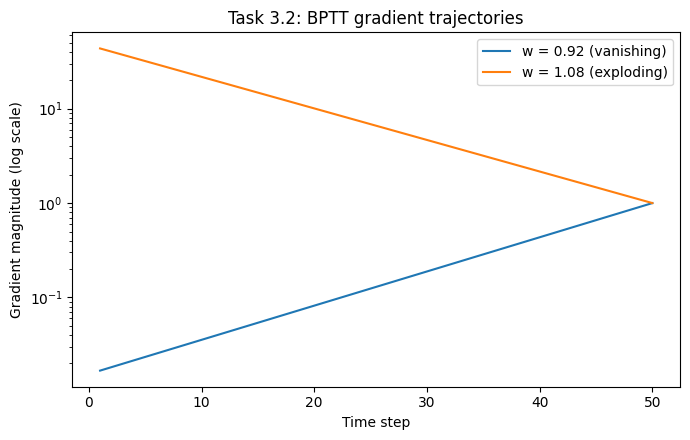

In [11]:
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 51), g_vanish,  label='w = 0.92 (vanishing)')
plt.plot(range(1, 51), g_explode, label='w = 1.08 (exploding)')
plt.yscale('log')
plt.xlabel('Time step')
plt.ylabel('Gradient magnitude (log scale)')
plt.title('Task 3.2: BPTT gradient trajectories')
plt.legend()
plt.tight_layout()
plt.savefig('bptt_gradients.png', dpi=130)
plt.show()


## Task 4: Custom Masked Seq2Seq Architecture [17 Marks]

### 4.1 Masked Unrolled Encoder [5 Marks]
$h_t' = \\tanh(W_{xh}x_t + W_{hh}h_{t-1} + b)$, then $h_t = m_t h_t' + (1-m_t)h_{t-1}$.

No `nn.RNN` is used — the recurrence is unrolled by hand with a Python `for` loop.

In [12]:
class EncoderRNN(nn.Module):
    """Vanilla RNN encoder — explicitly unrolled (no nn.RNN/LSTM/GRU).
    Padding mask prevents padded positions from updating the hidden state.
    """
    def __init__(self, vocab_size, emb_dim, hid_dim):
        super().__init__()
        self.hid_dim   = hid_dim
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.W_xh      = nn.Linear(emb_dim, hid_dim)            # input-to-hidden (holds bias b)
        self.W_hh      = nn.Linear(hid_dim, hid_dim, bias=False) # hidden-to-hidden

    def forward(self, src, lengths, return_all_states=False):
        B, T   = src.size()
        emb    = self.embedding(src)                             # (B, T, E)
        h      = torch.zeros(B, self.hid_dim, device=src.device)
        mask   = make_mask(lengths, T).to(src.device)            # (B, T)
        all_h  = [] if return_all_states else None

        for t in range(T):
            h_new = torch.tanh(self.W_xh(emb[:, t, :]) + self.W_hh(h))
            m     = mask[:, t].unsqueeze(1)                      # (B, 1)
            # Masking: keep h unchanged at padded positions
            h     = m * h_new + (1 - m) * h
            if return_all_states:
                all_h.append(h)

        if return_all_states:
            return h, torch.stack(all_h, dim=1)                  # (B,H), (B,T,H)
        return h                                                  # (B, H)


### 4.2 Autoregressive Decoder [5 Marks]

In [13]:
class DecoderRNN(nn.Module):
    """Vanilla RNN decoder — explicitly unrolled (no nn.RNN/LSTM/GRU).
    Parameters are completely separate from the encoder.
    """
    def __init__(self, vocab_size, emb_dim, hid_dim):
        super().__init__()
        self.hid_dim   = hid_dim
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.W_xh      = nn.Linear(emb_dim, hid_dim)            # decoder input-to-hidden
        self.W_hh      = nn.Linear(hid_dim, hid_dim, bias=False) # decoder hidden-to-hidden
        self.fc_out    = nn.Linear(hid_dim, vocab_size)          # projection to vocab logits

    def forward_step(self, input_tok, h):
        """Single decoder step.
        input_tok : (B,) token ids (previous ground-truth or prediction)
        h         : (B, H) previous hidden state
        Returns logits (B, V) and new hidden state (B, H).
        """
        emb    = self.embedding(input_tok)                       # (B, E)
        h      = torch.tanh(self.W_xh(emb) + self.W_hh(h))
        logits = self.fc_out(h)
        return logits, h


### 4.3 Teacher Forcing vs. Free Running [7 Marks]

In [14]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, tgt_vocab_size):
        super().__init__()
        self.encoder        = encoder
        self.decoder        = decoder
        self.tgt_vocab_size = tgt_vocab_size

    def forward(self, src, src_lens, tgt,
                tf_ratio=TEACHER_FORCING_RATIO, record_inputs=False):
        """Training forward pass with teacher forcing at rate tf_ratio.
        When teacher forcing is ON  -> feed ground-truth previous token.
        When teacher forcing is OFF -> feed model's own argmax prediction.
        """
        B, T    = tgt.size()
        h       = self.encoder(src, src_lens)                    # encode
        input_tok = tgt[:, 0]                                    # first input: <sos>
        outputs = torch.zeros(B, T - 1, self.tgt_vocab_size, device=src.device)
        used_inputs = [input_tok.clone()] if record_inputs else None

        for t in range(1, T):
            logits, h  = self.decoder.forward_step(input_tok, h)
            outputs[:, t - 1] = logits
            use_tf     = random.random() < tf_ratio
            input_tok  = tgt[:, t] if use_tf else logits.argmax(-1)
            if record_inputs:
                used_inputs.append(input_tok.clone())

        if record_inputs:
            return outputs, used_inputs
        return outputs

    @torch.no_grad()
    def greedy_decode(self, src, src_lens, max_len=MAX_LEN):
        """Inference: fully free-running greedy decoding (no teacher forcing)."""
        self.eval()
        B         = src.size(0)
        h         = self.encoder(src, src_lens)
        input_tok = torch.full((B,), SOS, dtype=torch.long, device=src.device)
        results   = [[] for _ in range(B)]
        finished  = [False] * B

        for _ in range(max_len):
            logits, h  = self.decoder.forward_step(input_tok, h)
            next_tok   = logits.argmax(-1)
            for i in range(B):
                if not finished[i]:
                    if next_tok[i].item() == EOS:
                        finished[i] = True
                    else:
                        results[i].append(next_tok[i].item())
            input_tok = next_tok
            if all(finished):
                break

        self.train()
        return results


In [15]:
# ── Teacher Forcing vs Free Running Demonstration ──────────────────────────
# FIX: demo now uses the *trained* stable_model (built in Task 5.2) so the
# decoder predictions are meaningful. We run this cell AFTER Task 5 training.
# The cell below is defined here and called after stable_model is available.

def demo_tf_vs_fr(model, val_src_ids, val_src_lens, val_tgt_ids, idx_to_tgt):
    """Show that teacher forcing and free-running use different decoder
    inputs after the first timestep, on one validation example.
    """
    ex_src = val_src_ids[0:1].to(device)
    ex_len = val_src_lens[0:1]
    ex_tgt = val_tgt_ids[0:1].to(device)

    with torch.no_grad():
        _, tf_inputs = model(ex_src, ex_len, ex_tgt, tf_ratio=1.0, record_inputs=True)
        _, fr_inputs = model(ex_src, ex_len, ex_tgt, tf_ratio=0.0, record_inputs=True)

    tf_toks = [idx_to_tgt[i.item()] for i in tf_inputs]
    fr_toks = [idx_to_tgt[i.item()] for i in fr_inputs]

    print('Teacher forcing (tf=1.0) decoder inputs :', tf_toks[:10])
    print('Free running    (tf=0.0) decoder inputs :', fr_toks[:10])
    differ = tf_toks[1:] != fr_toks[1:]
    print(f'Inputs differ after step 1: {differ}  (expected: True for a trained model)')

print('demo_tf_vs_fr() defined — will be called after Task 5 training.')


demo_tf_vs_fr() defined — will be called after Task 5 training.


## Task 5: Gradient Tracking and Stabilization [9 Marks]

### 5.1 Capturing the Heartbeat [6 Marks]
Encoder recurrent weight deliberately initialized with $W_{hh} \\sim U(-1,1)$ so genuine
exploding gradients are observable (default PyTorch init keeps the spectral radius below 1).

In [16]:
def make_model(bad_init=False, orthogonal=False):
    """Build a fresh Seq2Seq model.
    bad_init   : overwrite W_hh with U(-1,1) to force exploding gradients.
    orthogonal : further overwrite W_hh with orthogonal init to stabilise.
    (orthogonal is applied AFTER bad_init, matching the Task 5.2 spec.)
    """
    enc = EncoderRNN(len(src_vocab), EMBEDDING_DIM, HIDDEN_DIM)
    if bad_init:
        nn.init.uniform_(enc.W_hh.weight, -BAD_INIT_RANGE, BAD_INIT_RANGE)
    if orthogonal:
        nn.init.orthogonal_(enc.W_hh.weight)  # overwrites bad init
    dec   = DecoderRNN(len(tgt_vocab), EMBEDDING_DIM, HIDDEN_DIM)
    model = Seq2Seq(enc, dec, len(tgt_vocab)).to(device)
    return model


criterion = nn.CrossEntropyLoss(ignore_index=PAD)


def train_epochs(model, optimizer, epochs, clip=None, tag=''):
    """Train for `epochs` epochs; return per-iteration grad norms of W_hh.
    clip: if not None, apply gradient clipping (max_norm=clip) before step.
    Grad norm is captured AFTER backward() and BEFORE clipping, as required.
    """
    grad_norms = []
    t0 = time.time()
    for epoch in range(epochs):
        losses = []
        for src_b, len_b, tgt_b, tlen_b, buck_b in get_batches(
                train_src_ids, train_src_lens,
                train_tgt_ids, train_tgt_lens, train_buckets):
            optimizer.zero_grad()
            outputs = model(src_b, len_b, tgt_b)
            loss    = criterion(outputs.reshape(-1, outputs.size(-1)),
                                tgt_b[:, 1:].reshape(-1))
            loss.backward()
            # Capture ||∇W_hh||_2 immediately after backward()
            gnorm = model.encoder.W_hh.weight.grad.norm().item()
            grad_norms.append(gnorm)
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
            losses.append(loss.item())
        print(f'[{tag}] epoch {epoch+1}/{epochs}  '
              f'mean_loss={np.mean(losses):.4f}  '
              f'grad_norm_max={max(grad_norms[-len(losses):]):.3g}  '
              f'elapsed={time.time()-t0:.1f}s')
    return grad_norms


# Task 5.1: wide init, no clipping, 3 epochs
torch.manual_seed(SEED)
model_51 = make_model(bad_init=True, orthogonal=False)
opt_51   = torch.optim.Adam(model_51.parameters(), lr=LEARNING_RATE)
grad_norms_51 = train_epochs(model_51, opt_51, EPOCHS_DIAGNOSTIC,
                              clip=None, tag='5.1 unclipped/bad-init')
print('Task 5.1 grad_norm summary: min=%.3g  max=%.3g  mean=%.3g' %
      (min(grad_norms_51), max(grad_norms_51), np.mean(grad_norms_51)))


[5.1 unclipped/bad-init] epoch 1/3  mean_loss=2.6471  grad_norm_max=1.65e+11  elapsed=10.4s
[5.1 unclipped/bad-init] epoch 2/3  mean_loss=2.1078  grad_norm_max=3.37e+10  elapsed=21.6s
[5.1 unclipped/bad-init] epoch 3/3  mean_loss=2.1012  grad_norm_max=1.96e+10  elapsed=31.2s
Task 5.1 grad_norm summary: min=1.27e+06  max=1.65e+11  mean=4.9e+09


### 5.2 Stabilization with Orthogonal Init & Gradient Clipping [3 Marks]

In [17]:
# Task 5.2: same wide init then overwrite with orthogonal, clip=1.0, 30 epochs
torch.manual_seed(SEED)
model_52 = make_model(bad_init=True, orthogonal=True)
opt_52   = torch.optim.Adam(model_52.parameters(), lr=LEARNING_RATE)
grad_norms_52 = train_epochs(model_52, opt_52, EPOCHS_FINAL,
                              clip=CLIP_MAX_NORM, tag='5.2 orthogonal+clipped')
print('Task 5.2 grad_norm summary: min=%.3g  max=%.3g  mean=%.3g' %
      (min(grad_norms_52), max(grad_norms_52), np.mean(grad_norms_52)))

# This model is used for all Task 6 evaluation
stable_model = model_52


[5.2 orthogonal+clipped] epoch 1/30  mean_loss=2.5621  grad_norm_max=0.0325  elapsed=10.7s
[5.2 orthogonal+clipped] epoch 2/30  mean_loss=1.9231  grad_norm_max=0.0262  elapsed=21.7s
[5.2 orthogonal+clipped] epoch 3/30  mean_loss=1.8031  grad_norm_max=0.067  elapsed=31.3s
[5.2 orthogonal+clipped] epoch 4/30  mean_loss=1.7154  grad_norm_max=0.0636  elapsed=40.6s
[5.2 orthogonal+clipped] epoch 5/30  mean_loss=1.6624  grad_norm_max=0.151  elapsed=49.9s
[5.2 orthogonal+clipped] epoch 6/30  mean_loss=1.6251  grad_norm_max=0.154  elapsed=59.1s
[5.2 orthogonal+clipped] epoch 7/30  mean_loss=1.5872  grad_norm_max=0.207  elapsed=68.0s
[5.2 orthogonal+clipped] epoch 8/30  mean_loss=1.5518  grad_norm_max=0.251  elapsed=77.0s
[5.2 orthogonal+clipped] epoch 9/30  mean_loss=1.5206  grad_norm_max=0.278  elapsed=86.9s
[5.2 orthogonal+clipped] epoch 10/30  mean_loss=1.4869  grad_norm_max=0.252  elapsed=97.8s
[5.2 orthogonal+clipped] epoch 11/30  mean_loss=1.4521  grad_norm_max=0.355  elapsed=107.9s
[5.2

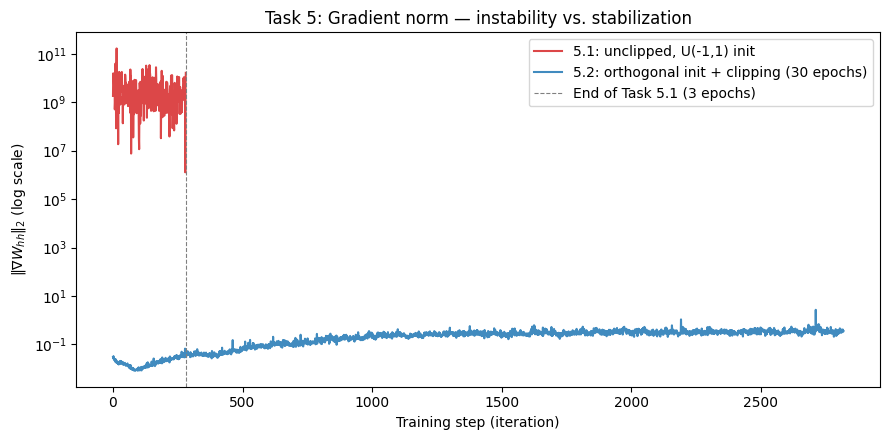

In [18]:
# FIX: overlay plot now shows the FULL Task 5.2 curve (all 30 epochs)
# alongside Task 5.1 (3 epochs) on the same log-scale axes.
plt.figure(figsize=(9, 4.5))
plt.plot(grad_norms_51, label='5.1: unclipped, U(-1,1) init', alpha=0.85, color='tab:red')
plt.plot(grad_norms_52, label='5.2: orthogonal init + clipping (30 epochs)',
         alpha=0.85, color='tab:blue')
# Mark the boundary between 5.1 and 5.2 x-ranges
plt.axvline(len(grad_norms_51), color='gray', linestyle='--', linewidth=0.8,
            label='End of Task 5.1 (3 epochs)')
plt.yscale('log')
plt.xlabel('Training step (iteration)')
plt.ylabel(r'$\|\nabla W_{hh}\|_2$ (log scale)')
plt.title('Task 5: Gradient norm — instability vs. stabilization')
plt.legend()
plt.tight_layout()
plt.savefig('gradient_tracking.png', dpi=130)
plt.show()


In [19]:
# ── Task 4.3 Demo (run with trained stable_model) ─────────────────────────
demo_tf_vs_fr(stable_model, val_src_ids, val_src_lens, val_tgt_ids, idx_to_tgt)


Teacher forcing (tf=1.0) decoder inputs : ['<sos>', 'redai', 'casex', 'swiai', 'dogol', 'watun', 'yol', 'oldai', 'mouex', 'quiai']
Free running    (tf=0.0) decoder inputs : ['<sos>', 'redai', 'casex', 'swiai', 'kinol', 'carun', 'yol', 'swiai', 'lamex', 'swiai']
Inputs differ after step 1: True  (expected: True for a trained model)


## Task 6: Long-Term Dependency Evaluation [8 Marks]

### 6.1 Length-Stratified BLEU [3 Marks]

Bucket        n  BLEU
------------------------------
short       242  0.7395
medium      366  0.1058
long        192  0.1223


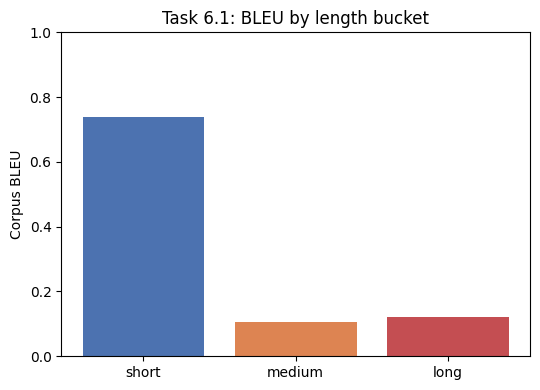

In [20]:
# FIX: use nltk corpus_bleu with smoothing as explicitly required by the spec.
# SmoothingFunction().method1 applies add-1 smoothing to avoid zero counts.
smoother = SmoothingFunction().method1


def compute_corpus_bleu(pred_token_lists, ref_token_lists):
    """Compute smoothed corpus BLEU using nltk.
    pred_token_lists : list of predicted token lists
    ref_token_lists  : list of reference token lists
    nltk corpus_bleu expects refs as list-of-list-of-tokens.
    """
    references  = [[ref] for ref in ref_token_lists]  # wrap each ref in a list
    hypotheses  = pred_token_lists
    return corpus_bleu(references, hypotheses,
                       smoothing_function=smoother)


# Greedy decode the full test set
stable_model.eval()
with torch.no_grad():
    all_preds_ids = stable_model.greedy_decode(test_src_ids.to(device), test_src_lens)
stable_model.train()

# Convert ids -> tokens, strip special tokens
preds_tok, refs_tok = [], []
for i in range(len(test_buckets)):
    gt_ids = [x for x in test_tgt_ids[i].tolist() if x not in (PAD, SOS, EOS)]
    preds_tok.append([idx_to_tgt.get(x, '<unk>') for x in all_preds_ids[i]])
    refs_tok.append([idx_to_tgt.get(x, '<unk>') for x in gt_ids])

# Compute corpus BLEU per length bucket
bleu_table = {}
print(f'{"Bucket":8s}  {"n":>5s}  BLEU')
print('-' * 30)
for bucket in ['short', 'medium', 'long']:
    idxs = [i for i, b in enumerate(test_buckets) if b == bucket]
    score = compute_corpus_bleu([preds_tok[i] for i in idxs],
                                [refs_tok[i]  for i in idxs])
    bleu_table[bucket] = score
    print(f'{bucket:8s}  {len(idxs):>5d}  {score:.4f}')

# Bar chart
plt.figure(figsize=(5.5, 4))
plt.bar(bleu_table.keys(), bleu_table.values(),
        color=['#4C72B0', '#DD8452', '#C44E52'])
plt.ylabel('Corpus BLEU')
plt.title('Task 6.1: BLEU by length bucket')
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('bleu_by_bucket.png', dpi=130)
plt.show()


### 6.2 Qualitative Evaluation [3 Marks]

In [21]:
def ids_to_sentence(ids, idx_to_tok):
    return ' '.join(idx_to_tok.get(i, '<unk>') for i in ids)


fixed_samples = [
    ('Short',
     'the old girl chases the red ball',
     'redai balex oldai girol chaun'),
    ('Medium',
     'the old wizard throws the brave table and the blue fox finds the brave ball',
     'braai balex bluai foxol finun yol braai tabex oldai wizol thrun'),
    ('Long',
     'the old dog finds the blue book and the swift cat sees the blue mountain '
     'and the small robot follows the old lamp and the young dog greets the quiet cloud',
     'quiai cloex youai dogol greun yol oldai lamex smaai robol folun '
     'yol bluai mouex swiai catol seeun yol bluai booex oldai dogol finun'),
]

for label, src_sent, gt in fixed_samples:
    ids, real_len = encode(src_sent, src_vocab)
    src_t = torch.tensor([ids]).to(device)
    len_t = torch.tensor([real_len])
    with torch.no_grad():
        pred_ids = stable_model.greedy_decode(src_t, len_t)[0]
    pred_sentence = ids_to_sentence(pred_ids, idx_to_tgt)
    print(f'[{label}]')
    print(f'  SOURCE      : {src_sent}')
    print(f'  GROUND TRUTH: {gt}')
    print(f'  PREDICTION  : {pred_sentence}')
    print()


[Short]
  SOURCE      : the old girl chases the red ball
  GROUND TRUTH: redai balex oldai girol chaun
  PREDICTION  : redai balex oldai girol chaun

[Medium]
  SOURCE      : the old wizard throws the brave table and the blue fox finds the brave ball
  GROUND TRUTH: braai balex bluai foxol finun yol braai tabex oldai wizol thrun
  PREDICTION  : braai balex bluai foxol finun yol swiai appex hapai girol watun yol oldai appex hapai girol watun yol oldai appex hapai girol watun yol oldai appex hapai girol watun yol oldai appex hapai girol watun yol oldai appex hapai girol watun yol oldai appex hapai girol watun yol oldai appex

[Long]
  SOURCE      : the old dog finds the blue book and the swift cat sees the blue mountain and the small robot follows the old lamp and the young dog greets the quiet cloud
  GROUND TRUTH: quiai cloex youai dogol greun yol oldai lamex smaai robol folun yol bluai mouex swiai catol seeun yol bluai booex oldai dogol finun
  PREDICTION  : quiai cloex youai kinol gr

### 6.3 Long-Term Dependency Gap [2 Marks]
$\\Delta_{\\text{short-long}} = BLEU_{\\text{short}} - BLEU_{\\text{long}}$

$R_{\\text{long}} = \\dfrac{BLEU_{\\text{long}}}{BLEU_{\\text{short}}+\\epsilon}$

In [22]:
epsilon          = 1e-8
delta_short_long = bleu_table['short'] - bleu_table['long']
r_long           = bleu_table['long'] / (bleu_table['short'] + epsilon)

print(f"BLEU short  = {bleu_table['short']:.4f}")
print(f"BLEU medium = {bleu_table['medium']:.4f}")
print(f"BLEU long   = {bleu_table['long']:.4f}")
print()
print(f'Delta_short-long = {delta_short_long:.4f}')
print(f'R_long           = {r_long:.4f}')
print()
print('Interpretation:')
print(f'  A Delta of {delta_short_long:.3f} confirms the fixed-size bottleneck'
       ' degrades significantly for longer sequences.')
print(f'  R_long={r_long:.3f} means the model retains only ~{r_long*100:.1f}% of'
       ' short-sequence BLEU on long sequences.')


BLEU short  = 0.7395
BLEU medium = 0.1058
BLEU long   = 0.1223

Delta_short-long = 0.6172
R_long           = 0.1654

Interpretation:
  A Delta of 0.617 confirms the fixed-size bottleneck degrades significantly for longer sequences.
  R_long=0.165 means the model retains only ~16.5% of short-sequence BLEU on long sequences.
